# 04 — Channel Analysis

During magnetoelectric stimulation, channels close to the stimulation source show
elevated logMUA ("saturated" channels). This notebook:

1. **Identifies stimulation files** using `parse_trial_id`.
2. **Computes per-channel logMUA statistics** (mean + variance) pooled across those files.
3. **Finds the KDE valley** separating high from low channels and prints results.
4. **Saves the groups** to `config.yaml` (fill `high_channels` / `low_channels`).
5. **Re-runs the full Up/Down analysis** for each group separately.
6. **Plots all comparison figures** (durations, SO freq, FR deltas, joint scatter)
   mirroring notebook 03 but split by channel group.

> **Channel numbering:** data channels are 0-based (0–31). All plots and printed
> output use 1-based labels (+1 offset) for consistency with your hardware.


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy
%matplotlib inline

from src.config import load_config
from src.data_io import list_h5_files, get_slice_id
from src.utils import parse_trial_id, get_stimulation_files
from src.channel_analysis import compute_channel_stats, classify_channels, make_group_cfg
from src import visualization as viz

cfg = load_config()
print('Conditions:', cfg['conditions'])
print('Processed dir:', cfg['paths']['processed_dir'])


Conditions: ['baseline', 'stimulation', 'post_stimulation']
Processed dir: c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data/processed


## 1. Identify stimulation files

In [3]:
all_h5 = list_h5_files(cfg['paths']['condition_dir'])
conditions = cfg['conditions']

# get_stimulation_files filters by the 'stimulation' condition suffix
stim_files = get_stimulation_files(all_h5, conditions, stim_condition='stimulation')

print(f'Total .h5 files : {len(all_h5)}')
print(f'Stimulation files: {len(stim_files)}')
for f in stim_files:
    print(' ', os.path.basename(f))


Total .h5 files : 9
Stimulation files: 3
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_stimulation.h5


## 2. Compute per-channel logMUA statistics

This pools mean and variance of logMUA across all stimulation files for every channel.

In [4]:
if not stim_files:
    print('No stimulation files found. Check your file naming and conditions list.')
else:
    stats_df = compute_channel_stats(stim_files, cfg)
    print('\nPer-channel stats (1-based channel labels):')
    display_df = stats_df.copy()
    display_df.index = display_df['channel_1based']
    print(display_df[['channel_1based','mean_logmua','var_logmua','mean_mua', 'var_mua']].to_string())


Computing per-channel logMUA stats: 100%|██████████| 3/3 [00:03<00:00,  1.24s/it]


Per-channel stats (1-based channel labels):
                channel_1based  mean_logmua  var_logmua   mean_mua       var_mua
channel_1based                                                                  
1                            1     0.786546    0.039578  29.834445   1287.191348
2                            2     0.762356    0.030126  26.038214    597.012413
3                            3     0.845362    0.022418  32.928991    490.463971
4                            4     0.879804    0.023614  32.902020    552.553233
5                            5     0.794902    0.021047  27.387849    254.981846
6                            6     0.771376    0.013850  22.229817    105.696983
7                            7     0.952217    0.053351  47.069913   2812.153313
8                            8     0.940124    0.048954  41.755896   1631.700883
9                            9     0.772567    0.012788  21.784537     55.795795
10                          10     0.700197    0.008873  18.3102

## 3. Find KDE valley threshold (LOG)

The distribution of mean logMUA across channels should be bimodal if some channels
are clearly saturated. The valley between the two modes is used as the threshold.

If the distribution is not bimodal (e.g. only a few channels are elevated), the
function falls back to a median split and warns you — in that case, set the groups
manually in `config.yaml`.


In [5]:
high_ch_0_mean, low_ch_0_mean, threshold_mean = classify_channels(stats_df, cfg, metric='mean_logmua')

# +1 offset for printing
high_ch_1_mean = [c + 1 for c in high_ch_0_mean]
low_ch_1_mean  = [c + 1 for c in low_ch_0_mean]

print(f'Threshold (mean logMUA): {threshold_mean:.4f}')
print(f'High channels (1-based, n={len(high_ch_1_mean)}): {high_ch_1_mean}')
print(f'Low  channels (1-based, n={len(low_ch_1_mean)}):  {low_ch_1_mean}')
print()
print('Add these to config.yaml → preprocessing:')
print(f'  high_channels: {high_ch_0_mean}   # 0-based')
print(f'  low_channels:  {low_ch_0_mean}    # 0-based')

high_ch_0_var, low_ch_0_var, threshold_var = classify_channels(stats_df, cfg, metric='var_logmua')

# +1 offset for printing
high_ch_1_var = [c + 1 for c in high_ch_0_var]
low_ch_1_var  = [c + 1 for c in low_ch_0_var]

print(f'Threshold (variance logMUA): {threshold_var:.4f}')
print(f'High channels (1-based, n={len(high_ch_1_var)}): {high_ch_1_var}')
print(f'Low  channels (1-based, n={len(low_ch_1_var)}):  {low_ch_1_var}')
print()
print('Add these to config.yaml → preprocessing:')
print(f'  high_channels: {high_ch_0_var}   # 0-based')
print(f'  low_channels:  {low_ch_0_var}    # 0-based')



Threshold (mean logMUA): 0.7781
High channels (1-based, n=16): [1, 3, 4, 5, 7, 8, 11, 12, 14, 19, 22, 25, 26, 27, 29, 30]
Low  channels (1-based, n=16):  [2, 6, 9, 10, 13, 15, 16, 17, 18, 20, 21, 23, 24, 28, 31, 32]

Add these to config.yaml → preprocessing:
  high_channels: [0, 2, 3, 4, 6, 7, 10, 11, 13, 18, 21, 24, 25, 26, 28, 29]   # 0-based
  low_channels:  [1, 5, 8, 9, 12, 14, 15, 16, 17, 19, 20, 22, 23, 27, 30, 31]    # 0-based
Threshold (variance logMUA): 0.0895
High channels (1-based, n=1): [14]
Low  channels (1-based, n=31):  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]

Add these to config.yaml → preprocessing:
  high_channels: [13]   # 0-based
  low_channels:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]    # 0-based


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_classification_mean.pdf


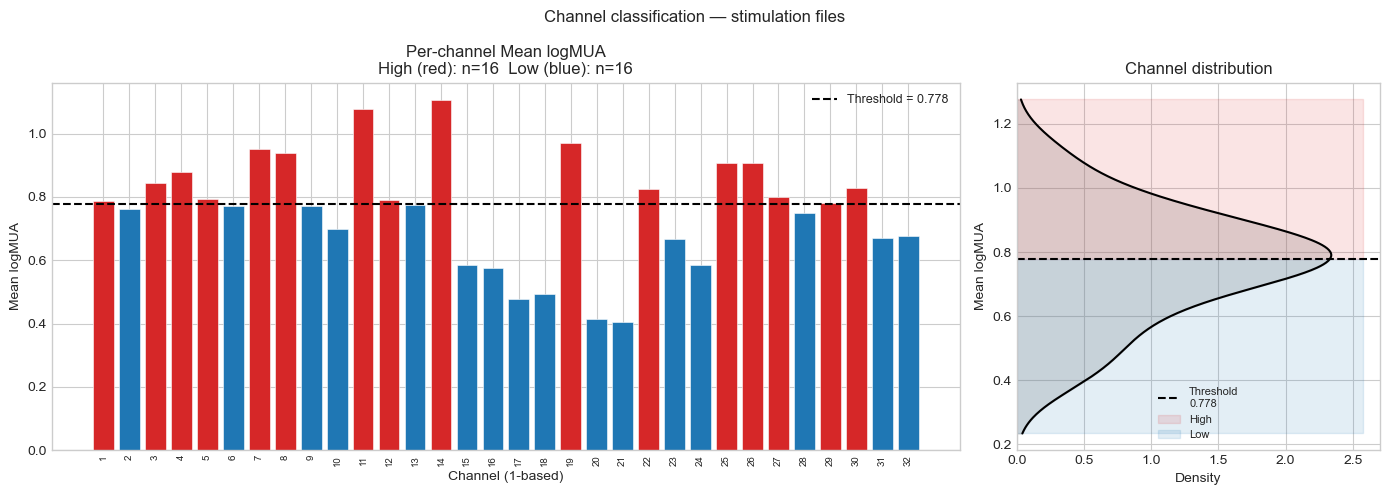

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_classification_var.pdf


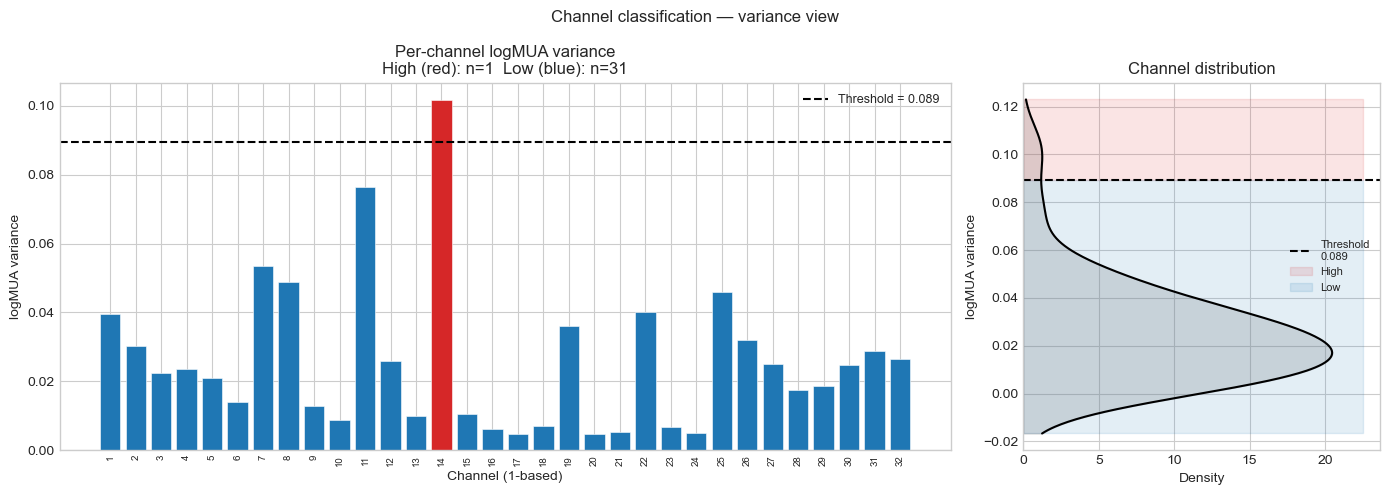

In [6]:
# --- Visualise the channel classification ---
fig, axes = viz.plot_channel_stats(
    stats_df, threshold_mean, high_ch_0_mean, low_ch_0_mean, cfg, metric='mean_logmua'
)
viz.save_figure(fig, 'ch_classification_mean', cfg)
plt.show()

# Also show variance-based view
fig2, _ = viz.plot_channel_stats(
    stats_df, threshold_var, high_ch_0_var, low_ch_0_var, cfg, metric='var_logmua'
)
fig2.suptitle('Channel classification — variance view', fontsize=12)
viz.save_figure(fig2, 'ch_classification_var', cfg)
plt.show()


## 3. (Part 2) Find the KDE Valley with the raw MUA

because why not

In [5]:
high_ch_0_mean, low_ch_0_mean, threshold_mean = classify_channels(stats_df, cfg, metric='mean_mua')

# +1 offset for printing
high_ch_1_mean = [c + 1 for c in high_ch_0_mean]
low_ch_1_mean  = [c + 1 for c in low_ch_0_mean]

print(f'Threshold (mean logMUA): {threshold_mean:.4f}')
print(f'High channels (1-based, n={len(high_ch_1_mean)}): {high_ch_1_mean}')
print(f'Low  channels (1-based, n={len(low_ch_1_mean)}):  {low_ch_1_mean}')
print()
print('Add these to config.yaml → preprocessing:')
print(f'  high_channels: {high_ch_0_mean}   # 0-based')
print(f'  low_channels:  {low_ch_0_mean}    # 0-based')

high_ch_0_var, low_ch_0_var, threshold_var = classify_channels(stats_df, cfg, metric='var_mua')

# +1 offset for printing
high_ch_1_var = [c + 1 for c in high_ch_0_var]
low_ch_1_var  = [c + 1 for c in low_ch_0_var]

print(f'Threshold (variance logMUA): {threshold_var:.4f}')
print(f'High channels (1-based, n={len(high_ch_1_var)}): {high_ch_1_var}')
print(f'Low  channels (1-based, n={len(low_ch_1_var)}):  {low_ch_1_var}')
print()
print('Add these to config.yaml → preprocessing:')
print(f'  high_channels: {high_ch_0_var}   # 0-based')
print(f'  low_channels:  {low_ch_0_var}    # 0-based')



Threshold (mean logMUA): 24.5375
High channels (1-based, n=16): [1, 2, 3, 4, 5, 7, 8, 11, 12, 14, 19, 22, 25, 26, 27, 30]
Low  channels (1-based, n=16):  [6, 9, 10, 13, 15, 16, 17, 18, 20, 21, 23, 24, 28, 29, 31, 32]

Add these to config.yaml → preprocessing:
  high_channels: [0, 1, 2, 3, 4, 6, 7, 10, 11, 13, 18, 21, 24, 25, 26, 29]   # 0-based
  low_channels:  [5, 8, 9, 12, 14, 15, 16, 17, 19, 20, 22, 23, 27, 28, 30, 31]    # 0-based
Threshold (variance logMUA): 298.0835
High channels (1-based, n=16): [1, 2, 3, 4, 7, 8, 11, 14, 19, 22, 25, 26, 27, 30, 31, 32]
Low  channels (1-based, n=16):  [5, 6, 9, 10, 12, 13, 15, 16, 17, 18, 20, 21, 23, 24, 28, 29]

Add these to config.yaml → preprocessing:
  high_channels: [0, 1, 2, 3, 6, 7, 10, 13, 18, 21, 24, 25, 26, 29, 30, 31]   # 0-based
  low_channels:  [4, 5, 8, 9, 11, 12, 14, 15, 16, 17, 19, 20, 22, 23, 27, 28]    # 0-based


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_classification_mean.pdf


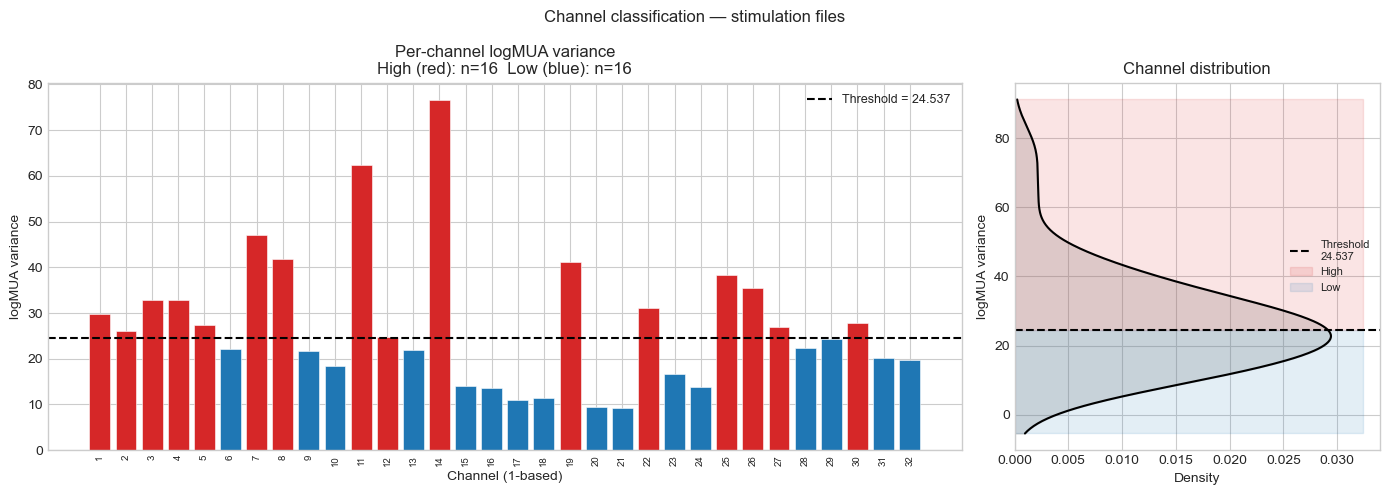

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_classification_var.pdf


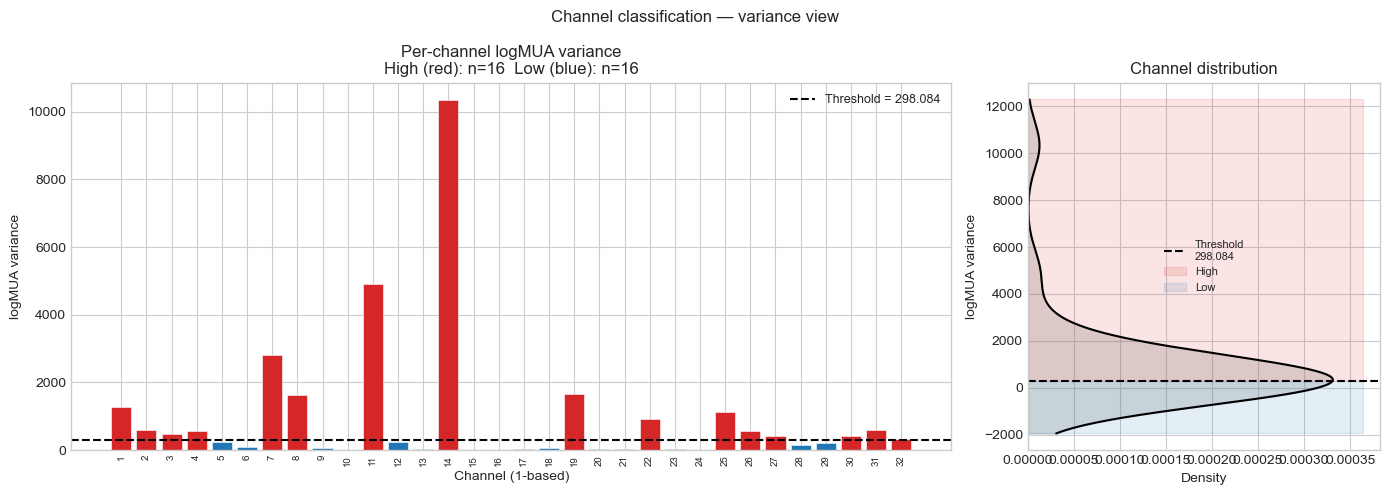

In [6]:
# --- Visualise the channel classification ---
fig, axes = viz.plot_channel_stats(
    stats_df, threshold_mean, high_ch_0_mean, low_ch_0_mean, cfg, metric='mean_mua'
)
viz.save_figure(fig, 'ch_classification_mean', cfg)
plt.show()

# Also show variance-based view
fig2, _ = viz.plot_channel_stats(
    stats_df, threshold_var, high_ch_0_var, low_ch_0_var, cfg, metric='var_mua'
)
fig2.suptitle('Channel classification — variance view', fontsize=12)
viz.save_figure(fig2, 'ch_classification_var', cfg)
plt.show()


In [4]:
high_ch_0_var, low_ch_0_var, threshold_var = classify_channels(stats_df, cfg, metric='log_var_mua')

# +1 offset for printing
high_ch_1_var = [c + 1 for c in high_ch_0_var]
low_ch_1_var  = [c + 1 for c in low_ch_0_var]

print(f'Threshold (variance logMUA): {threshold_var:.4f}')
print(f'High channels (1-based, n={len(high_ch_1_var)}): {high_ch_1_var}')
print(f'Low  channels (1-based, n={len(low_ch_1_var)}):  {low_ch_1_var}')
print()
print('Add these to config.yaml → preprocessing:')
print(f'  high_channels: {high_ch_0_var}   # 0-based')
print(f'  low_channels:  {low_ch_0_var}    # 0-based')


Threshold (variance logMUA): 4.1182
High channels (1-based, n=21): [1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 14, 19, 22, 25, 26, 27, 28, 29, 30, 31, 32]
Low  channels (1-based, n=11):  [9, 10, 13, 15, 16, 17, 18, 20, 21, 23, 24]

Add these to config.yaml → preprocessing:
  high_channels: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 13, 18, 21, 24, 25, 26, 27, 28, 29, 30, 31]   # 0-based
  low_channels:  [8, 9, 12, 14, 15, 16, 17, 19, 20, 22, 23]    # 0-based


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_classification_var.pdf


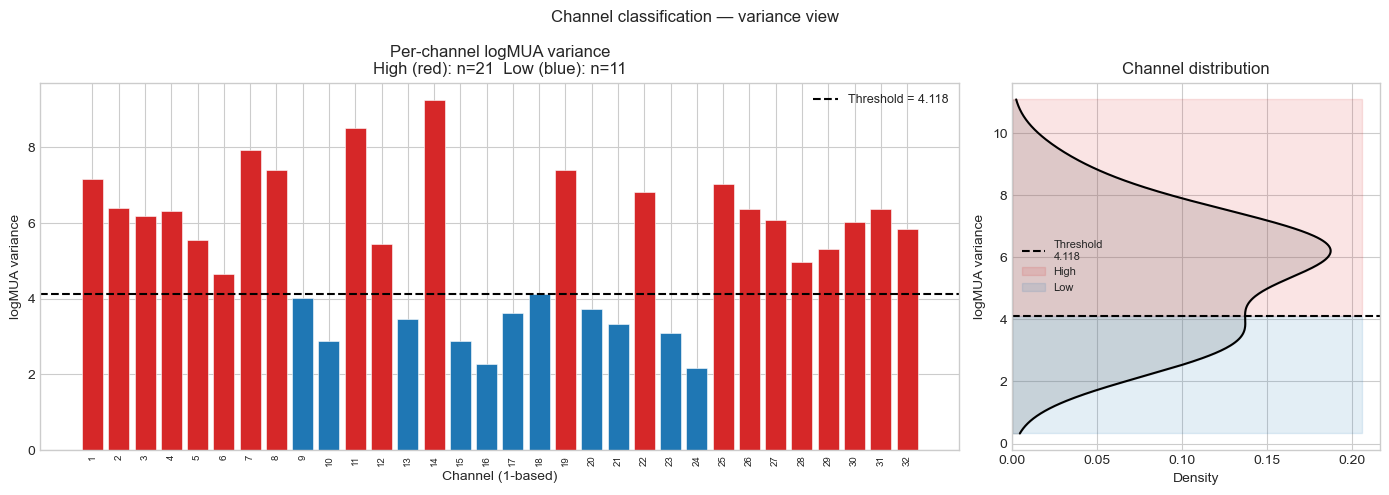

In [5]:
# Also show variance-based view
fig, _ = viz.plot_channel_stats(
    stats_df, threshold_var, high_ch_0_var, low_ch_0_var, cfg, metric='log_var_mua'
)
fig.suptitle('Channel classification — variance view', fontsize=12)
viz.save_figure(fig, 'ch_classification_var', cfg)
plt.show()


## 4. Set channel groups

After inspecting the plots above, either:
- **Accept the auto-detected groups** (run the cell below as-is), or
- **Override manually** by editing `config.yaml → preprocessing → high_channels / low_channels`
  and re-running from cell 1.

The cell below stores the groups in `cfg` for the rest of this notebook.


In [7]:
# If you want to override the auto-detected groups, edit these lists.
# They are 0-based channel indices (as stored in the data).
# Leave as-is to use the auto-detected values.
HIGH_CHANNELS = high_ch_0_mean   # ← edit if needed
LOW_CHANNELS  = low_ch_0_mean    # ← edit if needed

print(f'Using HIGH channels (0-based): {HIGH_CHANNELS}')
print(f'  → 1-based labels: {[c+1 for c in HIGH_CHANNELS]}')
print(f'Using LOW  channels (0-based): {LOW_CHANNELS}')
print(f'  → 1-based labels: {[c+1 for c in LOW_CHANNELS]}')

# Build per-group config overrides
cfg_high = make_group_cfg(cfg, HIGH_CHANNELS)
cfg_low  = make_group_cfg(cfg, LOW_CHANNELS)


Using HIGH channels (0-based): [0, 2, 3, 4, 6, 7, 10, 11, 13, 18, 21, 24, 25, 26, 28, 29]
  → 1-based labels: [1, 3, 4, 5, 7, 8, 11, 12, 14, 19, 22, 25, 26, 27, 29, 30]
Using LOW  channels (0-based): [1, 5, 8, 9, 12, 14, 15, 16, 17, 19, 20, 22, 23, 27, 30, 31]
  → 1-based labels: [2, 6, 9, 10, 13, 15, 16, 17, 18, 20, 21, 23, 24, 28, 31, 32]


## 5. Run full Up/Down analysis for each channel group

We reuse `Experiment` exactly as before — the only difference is that
`cfg_high` / `cfg_low` have `preprocessing.channel` set to the relevant
channel list, so the LFP is averaged over those channels before all
downstream analysis.


In [8]:
from src.core.experiment import Experiment

def run_group_analysis(h5_paths, cfg_group, conditions, label):
    """Run Experiment on all files and return a concatenated summary DataFrame."""
    rows = []
    for h5_path in h5_paths:
        stem      = get_slice_id(h5_path)
        condition = None
        for cond in sorted(conditions, key=len, reverse=True):
            if stem.lower().endswith('_' + cond.lower()):
                condition = cond
                break
        if condition is None:
            print(f'  [SKIP] Cannot infer condition from {os.path.basename(h5_path)}')
            continue
        try:
            exp = Experiment(h5_path, condition=condition, cfg=cfg_group)
            exp.run()
            rows.append(exp.summary_row)
        except Exception as e:
            print(f'  [ERROR] {os.path.basename(h5_path)}: {e}')
    if not rows:
        return pd.DataFrame()
    df = pd.concat(rows, ignore_index=True)
    df['channel_group'] = label
    return df

print('Running HIGH channel group...')
summary_high = run_group_analysis(all_h5, cfg_high, conditions, 'high')

print('\nRunning LOW channel group...')
summary_low  = run_group_analysis(all_h5, cfg_low,  conditions, 'low')

print(f'\nHigh group: {len(summary_high)} rows')
print(f'Low  group: {len(summary_low)} rows')


Running HIGH channel group...
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline | baseline] Running full analysis...
  Loaded 140625 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (44800, 3), downsampled to 1000.0 Hz
  State detection: 6 Up states, 7 Down states (threshold = 3.968)
  Firing rates: mean Up FR = 0.969, mean Down FR = 0.675
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline | baseline] Done. Detected 6 Up states, 7 Down states.
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation | post_stimulation] Running full analysis...
  Loaded 140625 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (44800, 3), downsampled to 1000.0 Hz
  State detection: 3 Up states, 4 Down states (threshold = 3.565)
  Firing rates: mean Up FR = 1.659, mean Down FR = 0.727
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation | post_stimulation] Done. Detected 3 Up states, 4 Down states.
[20260414_SLICE3_C

## 6. Add trial_id and compute delta values

In [9]:
# Add trial_id column to both DataFrames
for df in [summary_high, summary_low]:
    if 'trial_id' not in df.columns and not df.empty:
        df['trial_id'] = df['slice_id'].apply(
            lambda s: parse_trial_id(s, conditions)
        )

baseline_cond    = cfg.get('baseline_condition', conditions[0])
comparison_conds = [c for c in conditions if c != baseline_cond]

def collect_deltas(summary_df, comparison_conds, baseline_cond):
    """
    Collect paired delta values (comparison - baseline) for durations and FRs.
    Returns dict: {comp_cond: {'up': [...], 'down': [...],
                               'fr_up': [...], 'fr_down': [...]}}
    """
    deltas = {c: {'up': [], 'down': [], 'fr_up': [], 'fr_down': []}
              for c in comparison_conds}

    for trial_id in summary_df['trial_id'].unique():
        tr = summary_df[summary_df['trial_id'] == trial_id]
        bl = tr[tr['condition'] == baseline_cond]
        if bl.empty:
            continue

        bl_up   = bl['mean_up_s'].values[0]
        bl_down = bl['mean_down_s'].values[0]
        bl_fr_up   = bl['mean_fr_up'].values[0]   if 'mean_fr_up'   in bl.columns else np.nan
        bl_fr_down = bl['mean_fr_down'].values[0] if 'mean_fr_down' in bl.columns else np.nan

        for comp in comparison_conds:
            cr = tr[tr['condition'] == comp]
            if cr.empty:
                for key in deltas[comp]:
                    deltas[comp][key].append(np.nan)
                continue

            deltas[comp]['up'].append(
                float(cr['mean_up_s'].values[0] - bl_up)
                if not np.isnan(bl_up) else np.nan)
            deltas[comp]['down'].append(
                float(cr['mean_down_s'].values[0] - bl_down)
                if not np.isnan(bl_down) else np.nan)
            deltas[comp]['fr_up'].append(
                float(cr['mean_fr_up'].values[0] - bl_fr_up)
                if ('mean_fr_up' in cr.columns and not np.isnan(bl_fr_up)) else np.nan)
            deltas[comp]['fr_down'].append(
                float(cr['mean_fr_down'].values[0] - bl_fr_down)
                if ('mean_fr_down' in cr.columns and not np.isnan(bl_fr_down)) else np.nan)

    return deltas

deltas_high = collect_deltas(summary_high, comparison_conds, baseline_cond)
deltas_low  = collect_deltas(summary_low,  comparison_conds, baseline_cond)

print('Deltas computed.')
for comp in comparison_conds:
    n_h = sum(1 for v in deltas_high[comp]['up'] if not np.isnan(v))
    n_l = sum(1 for v in deltas_low[comp]['up']  if not np.isnan(v))
    print(f'  {comp}: high={n_h} pairs, low={n_l} pairs')


Deltas computed.
  stimulation: high=3 pairs, low=3 pairs
  post_stimulation: high=3 pairs, low=3 pairs


## 7. Duration + SO frequency — high vs low channel groups

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_group_duration_so.pdf


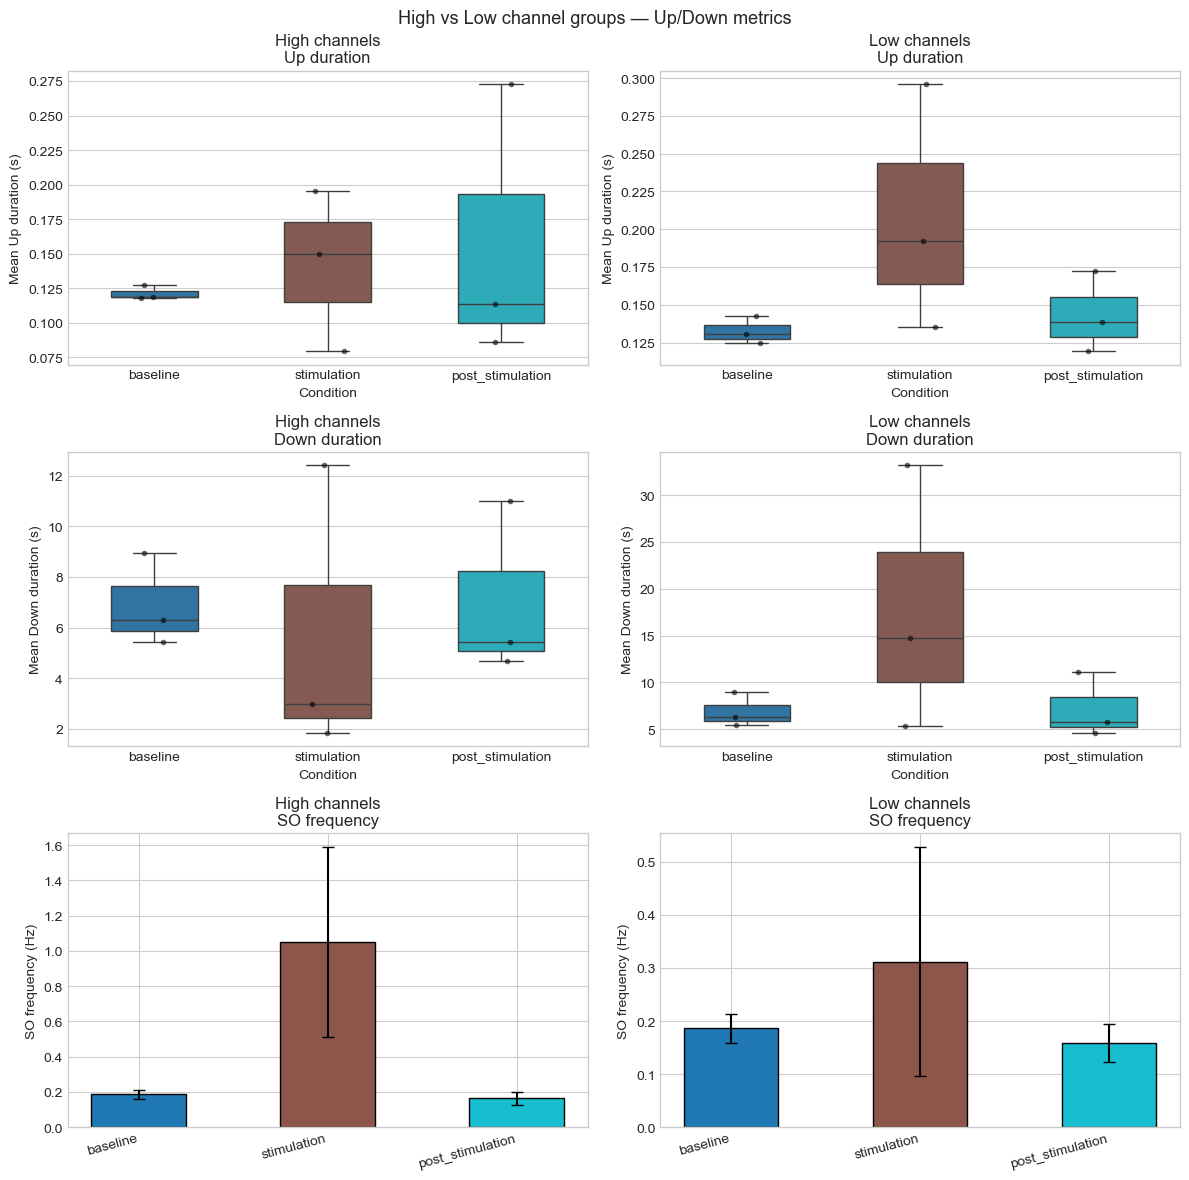

In [9]:
if not summary_high.empty and not summary_low.empty:
    fig, axes = viz.plot_group_comparison(summary_high, summary_low, cfg)
    viz.save_figure(fig, 'ch_group_duration_so', cfg)
    plt.show()


## 8. Δ Duration — high vs low, side by side

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_delta_duration_stimulation.pdf


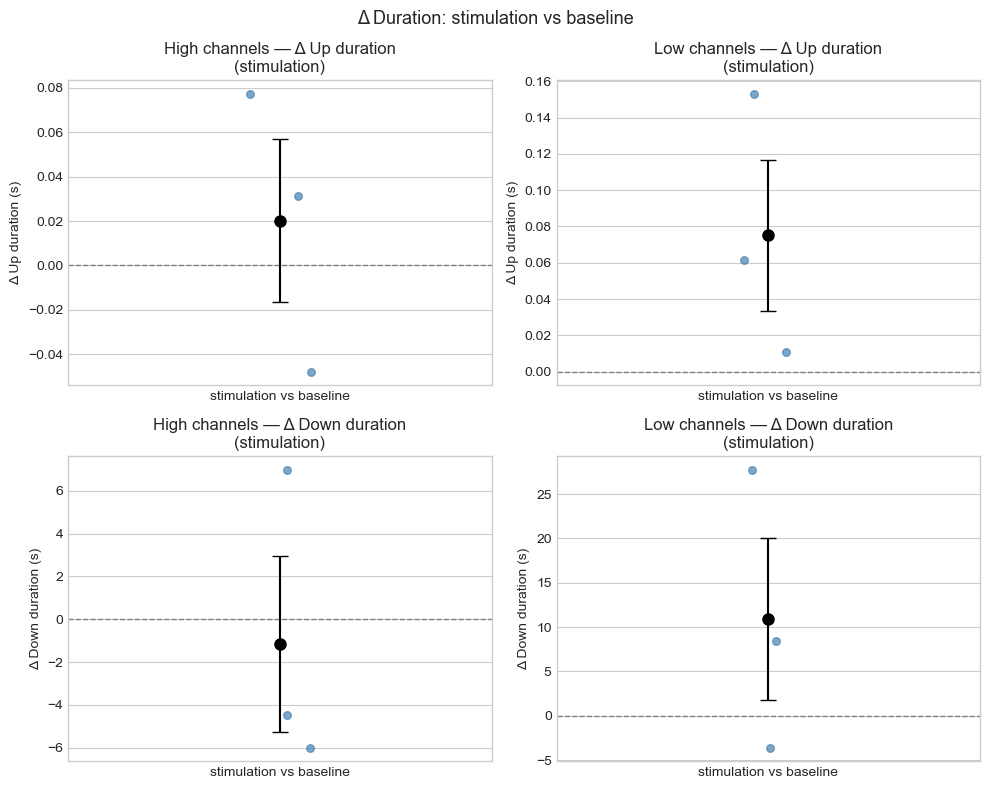

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_delta_duration_post_stimulation.pdf


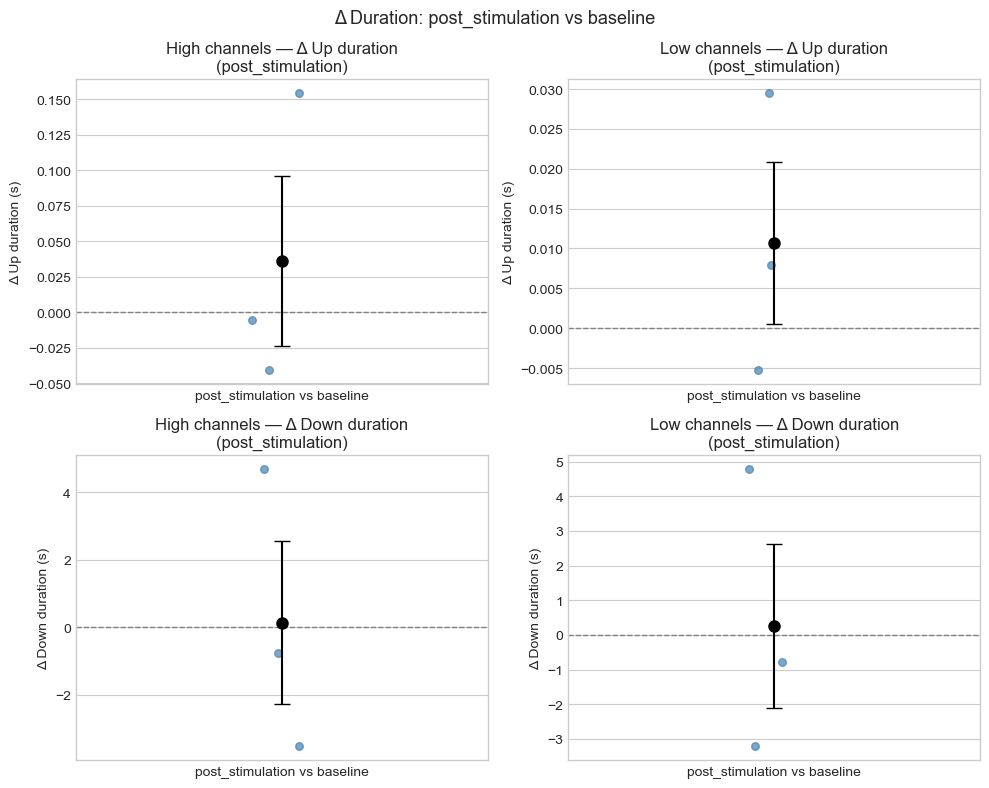

In [10]:
# For each comparison condition: 2 rows (Up/Down) × 2 cols (high/low)
for comp_cond in comparison_conds:
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    viz.plot_delta_duration(
        deltas_high[comp_cond]['up'],   comp_cond, 'up',   cfg, ax=axes[0, 0])
    axes[0, 0].set_title(f'High channels — Δ Up duration\n({comp_cond})')

    viz.plot_delta_duration(
        deltas_low[comp_cond]['up'],    comp_cond, 'up',   cfg, ax=axes[0, 1])
    axes[0, 1].set_title(f'Low channels — Δ Up duration\n({comp_cond})')

    viz.plot_delta_duration(
        deltas_high[comp_cond]['down'], comp_cond, 'down', cfg, ax=axes[1, 0])
    axes[1, 0].set_title(f'High channels — Δ Down duration\n({comp_cond})')

    viz.plot_delta_duration(
        deltas_low[comp_cond]['down'],  comp_cond, 'down', cfg, ax=axes[1, 1])
    axes[1, 1].set_title(f'Low channels — Δ Down duration\n({comp_cond})')

    fig.suptitle(f'Δ Duration: {comp_cond} vs {baseline_cond}', fontsize=13)
    plt.tight_layout()
    viz.save_figure(fig, f'ch_delta_duration_{comp_cond}', cfg)
    plt.show()


## 9. Joint Δup / Δdown scatter — high vs low overlaid

C:\Users\leosp\AppData\Local\Temp\ipykernel_10256\966599850.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_joint_delta_high_channels.pdf


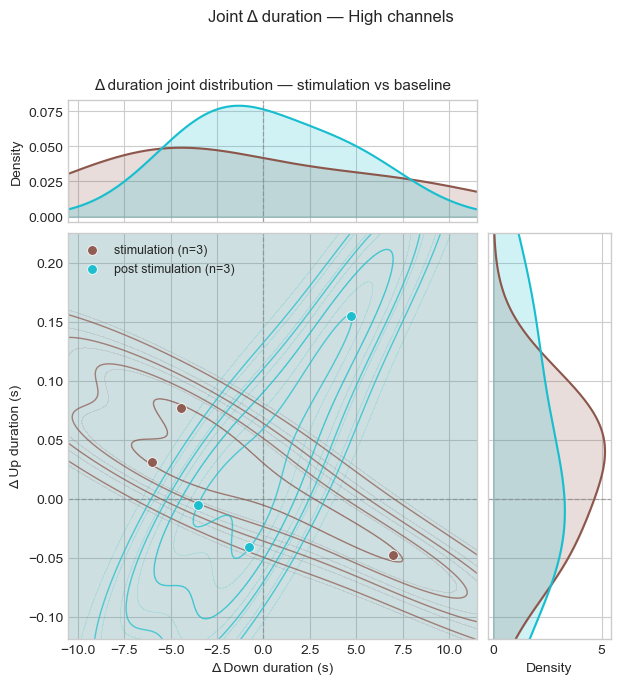

C:\Users\leosp\AppData\Local\Temp\ipykernel_10256\966599850.py:9: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_joint_delta_low_channels.pdf


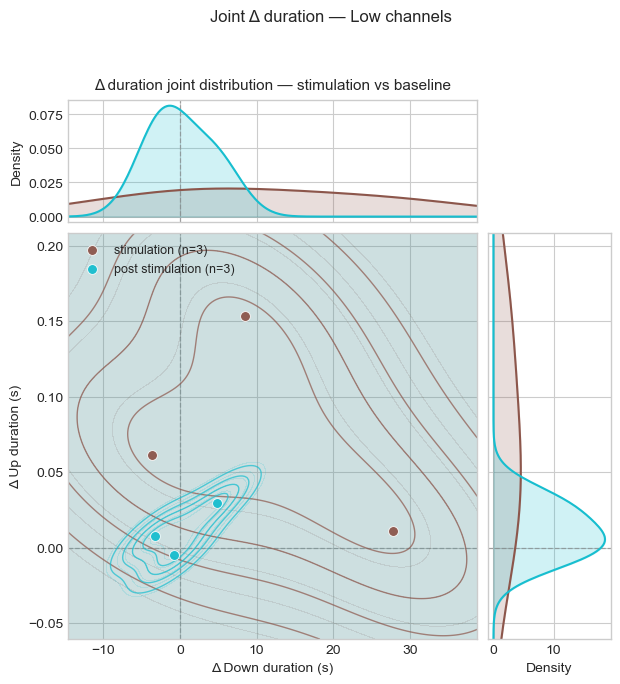

In [11]:
for group_label, deltas_g in [('High channels', deltas_high),
                               ('Low channels',  deltas_low)]:
    delta_data = {
        comp: (deltas_g[comp]['up'], deltas_g[comp]['down'])
        for comp in comparison_conds
    }
    fig = viz.plot_delta_duration_joint(delta_data, cfg)
    fig.suptitle(f'Joint Δ duration — {group_label}', fontsize=12, y=1.01)
    plt.tight_layout()
    viz.save_figure(fig, f'ch_joint_delta_{group_label.replace(" ","_").lower()}', cfg)
    plt.show()


## 11. Δ FR boxplots — all comparison conditions combined per group

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_up_high_channels.pdf


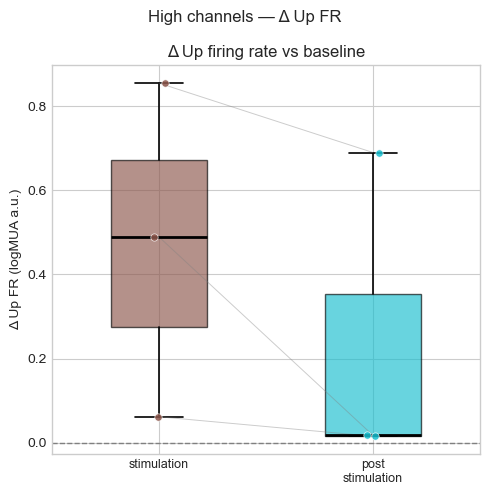

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_down_high_channels.pdf


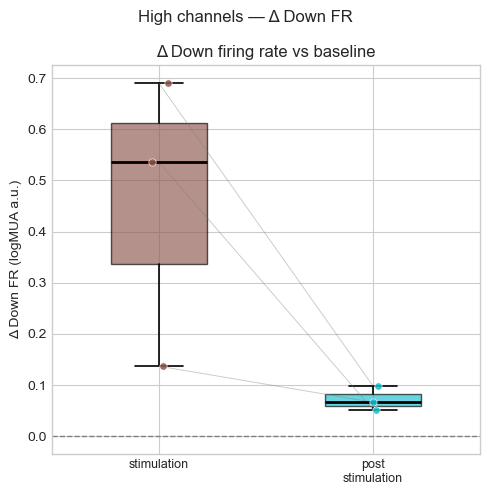

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_up_low_channels.pdf


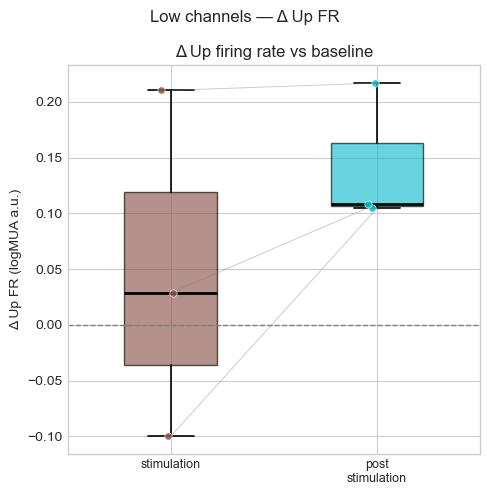

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_down_low_channels.pdf


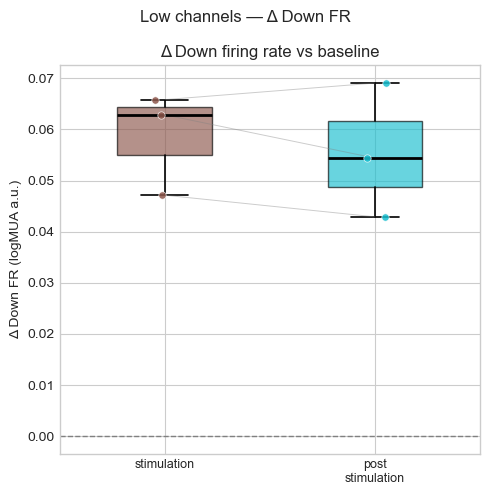

In [14]:
for group_label, deltas_g in [('High channels', deltas_high),
                               ('Low channels',  deltas_low)]:
    delta_fr_up   = {c: deltas_g[c]['fr_up']   for c in comparison_conds}
    delta_fr_down = {c: deltas_g[c]['fr_down']  for c in comparison_conds}

    fig_up, ax_up = viz.plot_delta_fr_boxplot(delta_fr_up,   'up',   cfg)
    fig_up.suptitle(f'{group_label} — Δ Up FR', fontsize=12)
    plt.tight_layout()
    viz.save_figure(fig_up, f'ch_fr_boxplot_up_{group_label.replace(" ","_").lower()}', cfg)
    plt.show()

    fig_dn, ax_dn = viz.plot_delta_fr_boxplot(delta_fr_down, 'down', cfg)
    fig_dn.suptitle(f'{group_label} — Δ Down FR', fontsize=12)
    plt.tight_layout()
    viz.save_figure(fig_dn, f'ch_fr_boxplot_down_{group_label.replace(" ","_").lower()}', cfg)
    plt.show()


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_delta_duration_stimulation.pdf


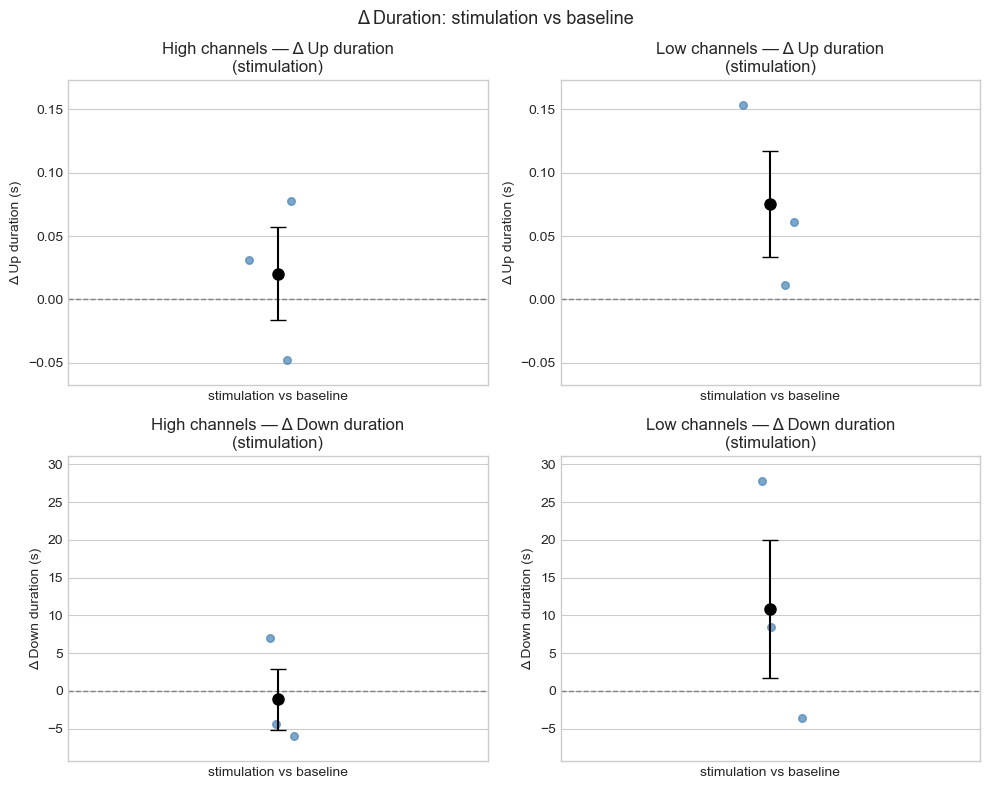

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_delta_duration_post_stimulation.pdf


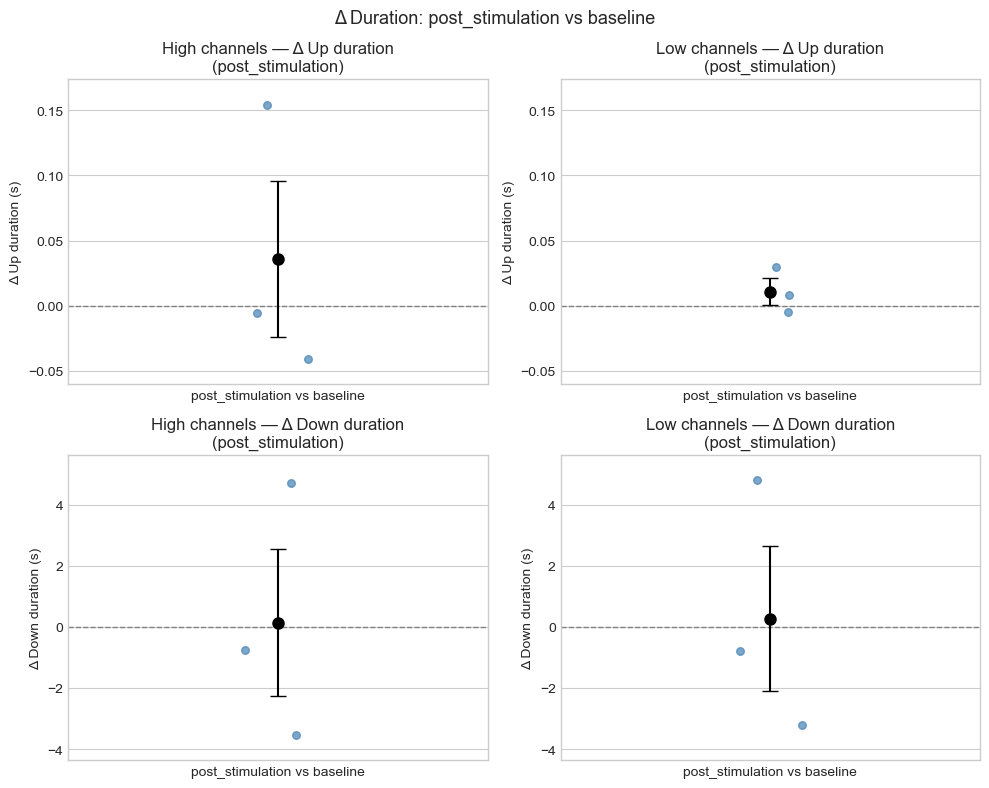

In [10]:
from src.utils import shared_ylims

for comp_cond in comparison_conds:
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    # --- Compute shared limits BEFORE plotting ---
    up_lims   = shared_ylims(deltas_high[comp_cond]['up'],
                             deltas_low[comp_cond]['up'])
    down_lims = shared_ylims(deltas_high[comp_cond]['down'],
                             deltas_low[comp_cond]['down'])

    # --- Plot ---
    viz.plot_delta_duration(deltas_high[comp_cond]['up'],   comp_cond, 'up',   cfg, ax=axes[0, 0])
    viz.plot_delta_duration(deltas_low[comp_cond]['up'],    comp_cond, 'up',   cfg, ax=axes[0, 1])
    viz.plot_delta_duration(deltas_high[comp_cond]['down'], comp_cond, 'down', cfg, ax=axes[1, 0])
    viz.plot_delta_duration(deltas_low[comp_cond]['down'],  comp_cond, 'down', cfg, ax=axes[1, 1])

    # --- Apply shared limits AFTER plotting ---
    axes[0, 0].set_ylim(*up_lims);   axes[0, 1].set_ylim(*up_lims)
    axes[1, 0].set_ylim(*down_lims); axes[1, 1].set_ylim(*down_lims)

    axes[0, 0].set_title(f'High channels — Δ Up duration\n({comp_cond})')
    axes[0, 1].set_title(f'Low channels — Δ Up duration\n({comp_cond})')
    axes[1, 0].set_title(f'High channels — Δ Down duration\n({comp_cond})')
    axes[1, 1].set_title(f'Low channels — Δ Down duration\n({comp_cond})')

    fig.suptitle(f'Δ Duration: {comp_cond} vs {baseline_cond}', fontsize=13)
    plt.tight_layout()
    viz.save_figure(fig, f'ch_delta_duration_{comp_cond}', cfg)
    plt.show()

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_up_high_channels.pdf
[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_down_high_channels.pdf


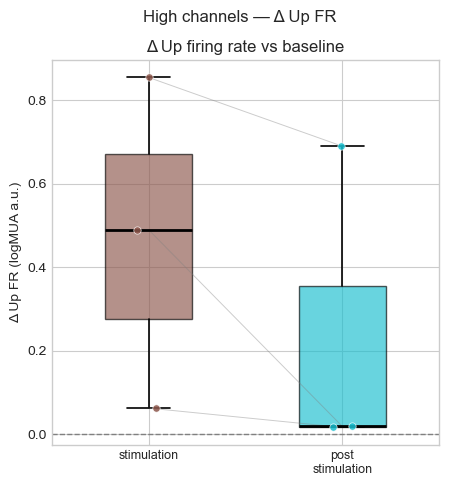

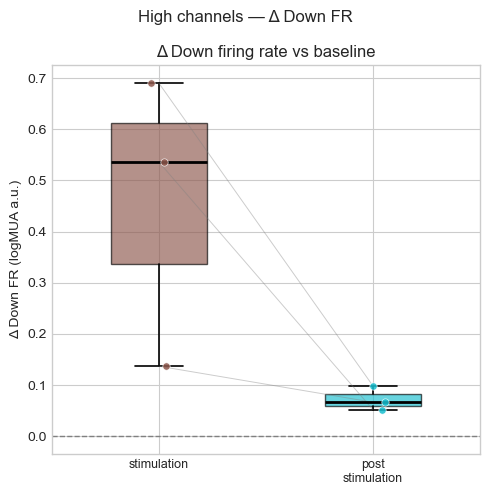

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_up_low_channels.pdf
[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_down_low_channels.pdf


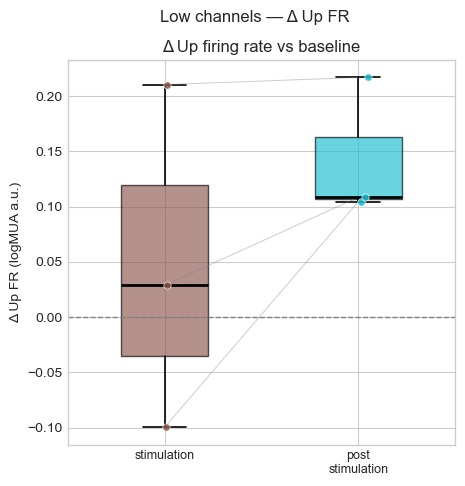

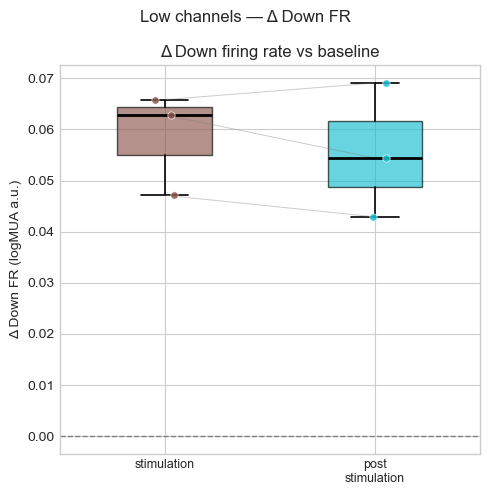

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\ch_fr_boxplot_combined_shared.pdf


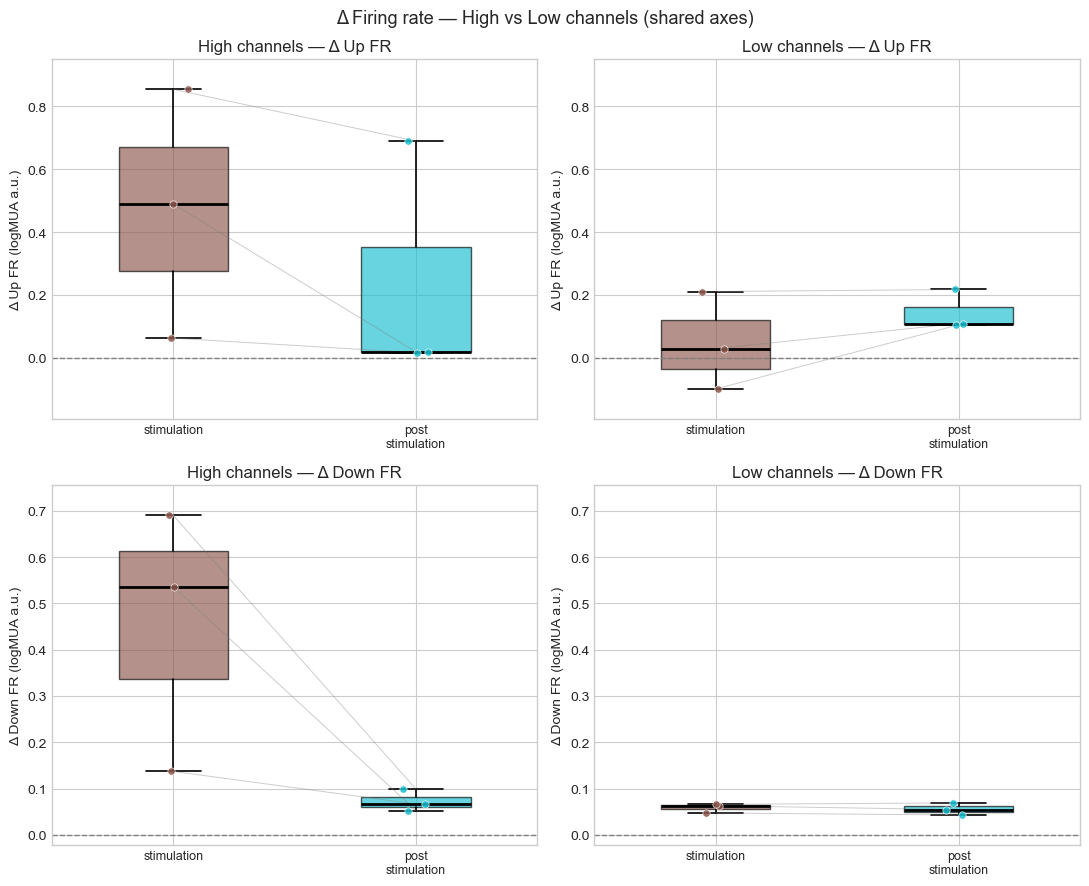

In [11]:
for group_label, deltas_g in [('High channels', deltas_high),
                               ('Low channels',  deltas_low)]:
    delta_fr_up   = {c: deltas_g[c]['fr_up']   for c in comparison_conds}
    delta_fr_down = {c: deltas_g[c]['fr_down']  for c in comparison_conds}

    fig_up, ax_up = viz.plot_delta_fr_boxplot(delta_fr_up,   'up',   cfg)
    fig_dn, ax_dn = viz.plot_delta_fr_boxplot(delta_fr_down, 'down', cfg)

    fig_up.suptitle(f'{group_label} — Δ Up FR',   fontsize=12)
    fig_dn.suptitle(f'{group_label} — Δ Down FR', fontsize=12)
    plt.tight_layout()
    viz.save_figure(fig_up, f'ch_fr_boxplot_up_{group_label.replace(" ","_").lower()}',   cfg)
    viz.save_figure(fig_dn, f'ch_fr_boxplot_down_{group_label.replace(" ","_").lower()}', cfg)
    plt.show()

# Synchronise the two Up boxplots and the two Down boxplots after the fact
# by re-opening the saved figures is not possible, so instead generate them
# together in one figure:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

all_fr_up_lims   = shared_ylims(
    *[deltas_high[c]['fr_up']   for c in comparison_conds],
    *[deltas_low[c]['fr_up']    for c in comparison_conds])
all_fr_down_lims = shared_ylims(
    *[deltas_high[c]['fr_down'] for c in comparison_conds],
    *[deltas_low[c]['fr_down']  for c in comparison_conds])

viz.plot_delta_fr_boxplot({c: deltas_high[c]['fr_up']   for c in comparison_conds}, 'up',   cfg, ax=axes[0, 0])
viz.plot_delta_fr_boxplot({c: deltas_low[c]['fr_up']    for c in comparison_conds}, 'up',   cfg, ax=axes[0, 1])
viz.plot_delta_fr_boxplot({c: deltas_high[c]['fr_down'] for c in comparison_conds}, 'down', cfg, ax=axes[1, 0])
viz.plot_delta_fr_boxplot({c: deltas_low[c]['fr_down']  for c in comparison_conds}, 'down', cfg, ax=axes[1, 1])

axes[0, 0].set_ylim(*all_fr_up_lims);   axes[0, 1].set_ylim(*all_fr_up_lims)
axes[1, 0].set_ylim(*all_fr_down_lims); axes[1, 1].set_ylim(*all_fr_down_lims)

axes[0, 0].set_title('High channels — Δ Up FR');   axes[0, 1].set_title('Low channels — Δ Up FR')
axes[1, 0].set_title('High channels — Δ Down FR'); axes[1, 1].set_title('Low channels — Δ Down FR')

fig.suptitle('Δ Firing rate — High vs Low channels (shared axes)', fontsize=13)
plt.tight_layout()
viz.save_figure(fig, 'ch_fr_boxplot_combined_shared', cfg)
plt.show()

## Next steps

- If the channel groups from the KDE look wrong, set `high_channels` and `low_channels`
  manually in `config.yaml → preprocessing` (0-based indices), then re-run from cell 1.
  The `classify_channels()` function will use those values directly on next run.
- To re-run just the analysis for one group with different channels, call
  `make_group_cfg(cfg, [ch1, ch2, ...])` and pass the result to `Experiment`.
